In [1]:
# Core libraries for data handling, numerical operations, and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Task1: Temporal Indexing and Initial Inspection

Load the provided daily bicycle dataset (daily_trips.csv), inspect its schema, check for missing values, and convert the date column into a proper DatetimeIndex.

Use pd.to_datetime() followed by .set_index().

In [2]:
# Load the raw daily bicycle trip dataset
daily_trips = pd.read_csv('daily_trips.csv')
daily_trips

,Unnamed: 0,starttime,tripduration,temperature
0,0,2014-01-01,1020.183333,19.483158
1,1,2014-01-02,1292.850000,16.833333
2,2,2014-01-03,58.383333,-5.633333
3,3,2014-01-04,2001.350000,30.007735
4,4,2014-01-05,393.133333,16.756250
...,...,...,...,...
1456,1456,2017-12-27,10348.683333,2.458013
1457,1457,2017-12-28,12129.600000,10.802762
1458,1458,2017-12-29,10690.933333,12.978932
1459,1459,2017-12-30,5054.866667,3.657033


In [3]:
# Inspect schema and check for missing values before converting types
daily_trips.info()

<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    1461 non-null   int64  
 1   starttime     1461 non-null   str    
 2   tripduration  1461 non-null   float64
 3   temperature   1458 non-null   float64
dtypes: float64(2), int64(1), str(1)
memory usage: 45.8 KB


In [4]:
# Convert starttime to datetime and promote it to a DatetimeIndex so the
# DataFrame can be resampled, sliced, and decomposed as a proper time series
daily_trips["starttime"] = pd.to_datetime(daily_trips['starttime'], format ='%Y-%m-%d')
daily_trips = daily_trips.set_index('starttime')
daily_trips.info()


<class 'pandas.DataFrame'>
DatetimeIndex: 1461 entries, 2014-01-01 to 2017-12-31
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    1461 non-null   int64  
 1   tripduration  1461 non-null   float64
 2   temperature   1458 non-null   float64
dtypes: float64(2), int64(1)
memory usage: 45.7 KB


In [5]:
# Confirm the index conversion worked as expected
daily_trips.head(10)


,Unnamed: 0,tripduration,temperature
starttime,,,
2014-01-01,0,1020.183333,19.483158
2014-01-02,1,1292.850000,16.833333
2014-01-03,2,58.383333,-5.633333
2014-01-04,3,2001.350000,30.007735
2014-01-05,4,393.133333,16.756250
2014-01-06,5,6.550000,-15.000000
2014-01-07,6,0.000000,NaN
2014-01-08,7,0.000000,NaN
2014-01-09,8,9357.566667,18.012034


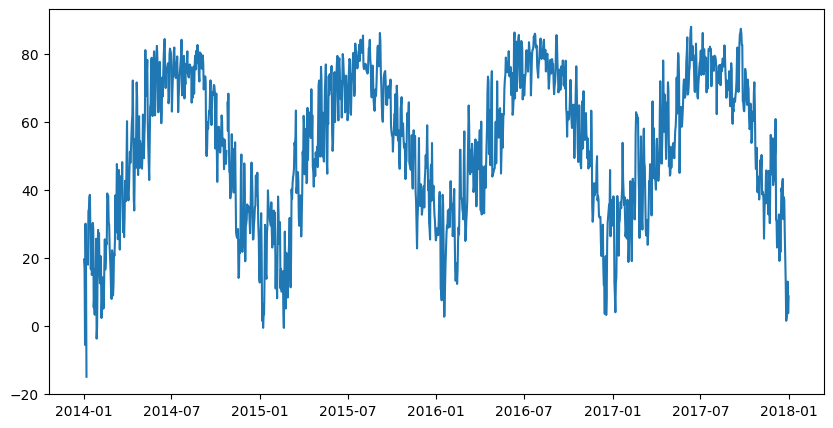

In [6]:
# Quick sanity-check plot of temperature over the full date range
plt.figure(figsize = (10,5))
plt.plot(daily_trips.index, daily_trips['temperature'])


## Task2: Resampling and Aggregation

Resample the daily data to monthly totals ('ME') using pandas .resample(). Save it to another variable.
Plot the resampled monthly data alongside the daily data to compare granularities.

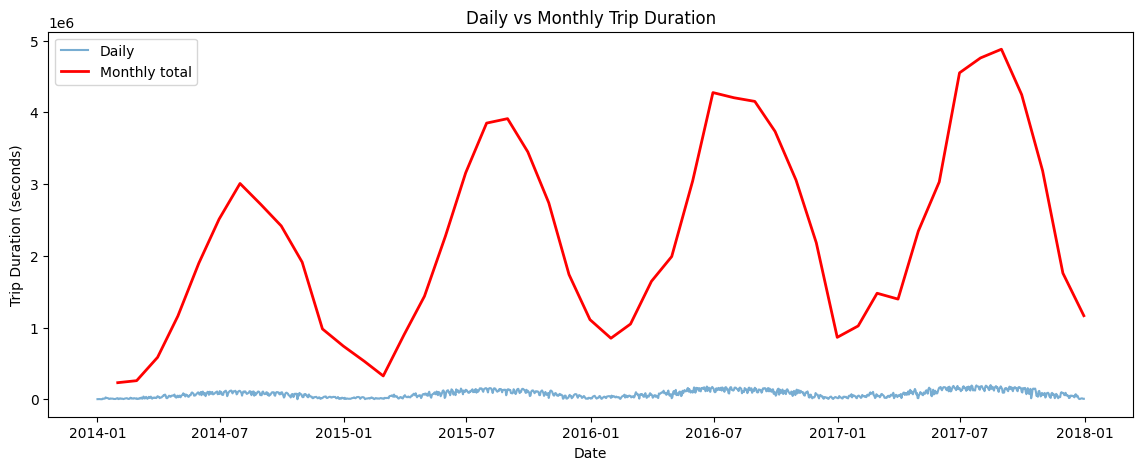

starttime
2014-01-31    2.306236e+05
2014-02-28    2.588342e+05
2014-03-31    5.845754e+05
2014-04-30    1.159495e+06
2014-05-31    1.896429e+06
2014-06-30    2.510605e+06
2014-07-31    3.008273e+06
2014-08-31    2.714209e+06
2014-09-30    2.416844e+06
2014-10-31    1.910991e+06
2014-11-30    9.801698e+05
2014-12-31    7.405097e+05
Freq: ME, Name: tripduration, dtype: float64

In [7]:
# Resample the daily trip duration to monthly totals ('ME' = month end)
daily_trips_monthly = daily_trips['tripduration'].resample('ME').sum()

# Overlay daily and monthly series to compare the two granularities
plt.figure(figsize=(14, 5))
plt.plot(daily_trips['tripduration'], label='Daily', alpha=0.6)
plt.plot(daily_trips_monthly, label='Monthly total', linewidth=2, color='red')
plt.title('Daily vs Monthly Trip Duration')
plt.xlabel('Date')
plt.ylabel('Trip Duration (seconds)')
plt.legend()
plt.show()

# Preview the first year of monthly totals
daily_trips_monthly.head(12)

## Task3: Exploratory Data Visualisation
Plot the daily trip duration and temperature trends over time.

Do you notice any immediate visual patterns, cycles, or anomalies (e.g., seasonality)?

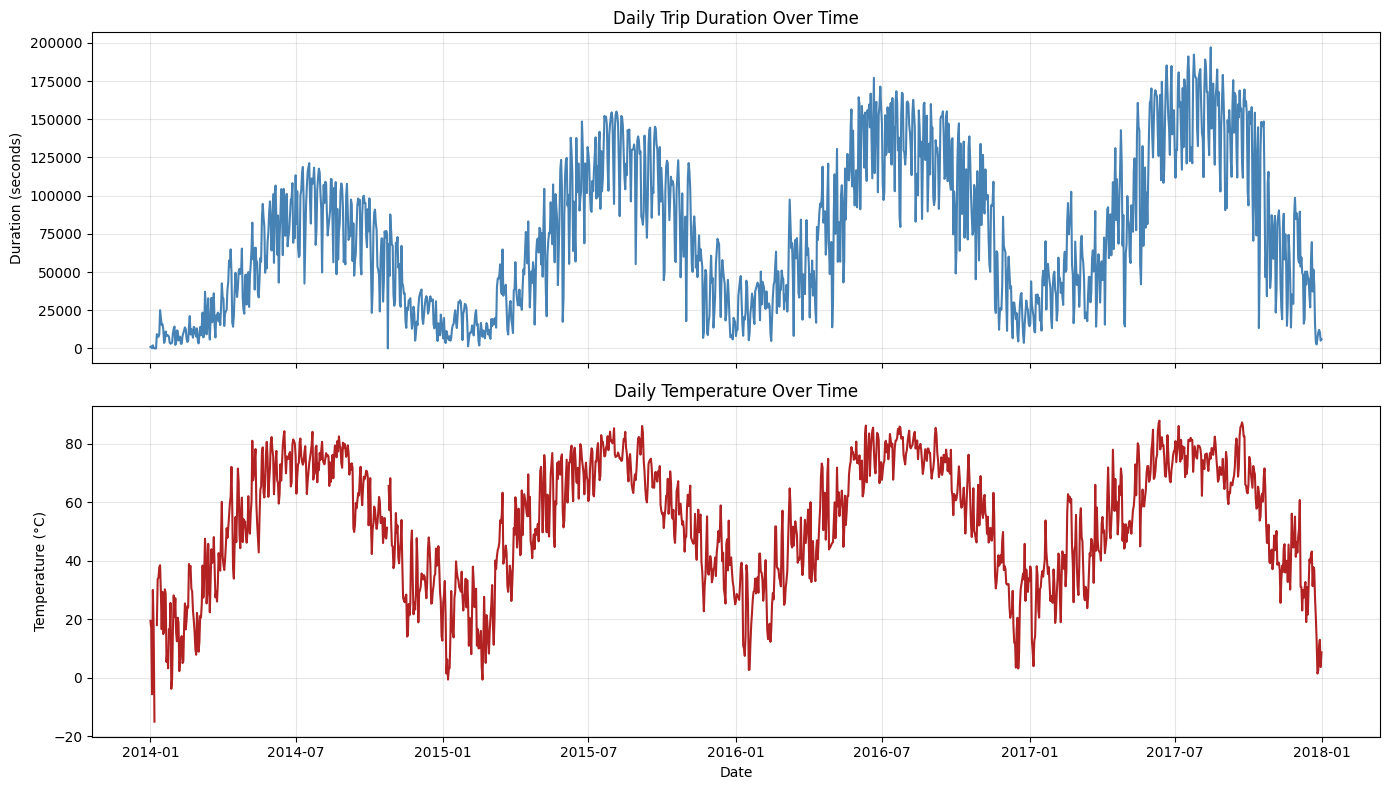

In [8]:
# Plot trip duration and temperature side by side to look for seasonality,
# cycles, or anomalies shared between the two series
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(daily_trips['tripduration'], color='steelblue')
axes[0].set_title('Daily Trip Duration Over Time')
axes[0].set_ylabel('Duration (seconds)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(daily_trips['temperature'], color='firebrick')
axes[1].set_title('Daily Temperature Over Time')
axes[1].set_ylabel('Temperature (°C)')
axes[1].set_xlabel('Date')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Task 4: Time Series Decomposition

Perform an additive or multiplicative decomposition on your monthly resampled series.

Extract and plot the Trend and Seasonal sub-plots. Briefly write a 2-sentence description of what the trend tells you about bicycle rentals over the years.

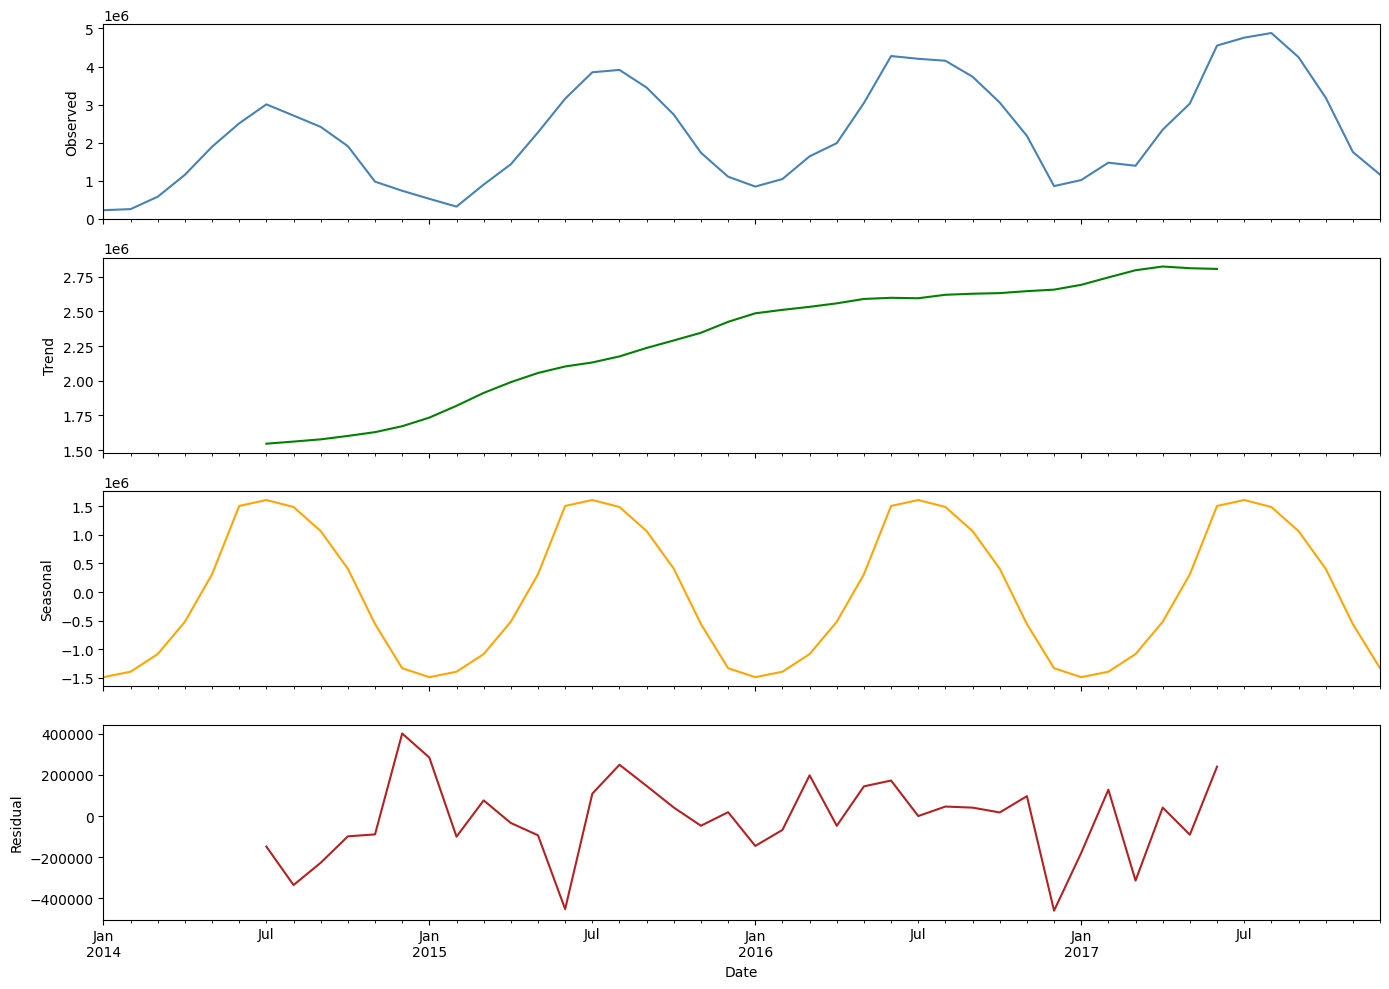

In [9]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Additive decomposition splits the monthly series into trend, seasonal,
# and residual components; period=12 reflects the yearly seasonal cycle
decomposition = seasonal_decompose(daily_trips_monthly, model='additive', period=12)

# Plot each component in its own subplot for easier comparison
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
decomposition.observed.plot(ax=axes[0], color='steelblue')
axes[0].set_ylabel('Observed')
decomposition.trend.plot(ax=axes[1], color='green')
axes[1].set_ylabel('Trend')
decomposition.seasonal.plot(ax=axes[2], color='orange')
axes[2].set_ylabel('Seasonal')
decomposition.resid.plot(ax=axes[3], color='firebrick')
axes[3].set_ylabel('Residual')
axes[3].set_xlabel('Date')
plt.tight_layout()
plt.show()

## Task 5: Stationarity Check (The Final Test)

Run the Augmented Dickey-Fuller (ADF) test on the monthly series to check for stationarity.

If the p-value is above 0.05 (non-stationary), apply a transformation (like differencing) and re-run the ADF test until the series becomes stationary.

In [10]:
from statsmodels.tsa.stattools import adfuller

# Runs the Augmented Dickey-Fuller test and prints the statistic, p-value,
# and critical values; returns the p-value so callers can decide whether
# further differencing is needed
def run_adf_test(series, label):
    result = adfuller(series.dropna())
    print(f"--- ADF Test: {label} ---")
    print(f"ADF Statistic: {result[0]:.6f}")
    print(f"p-value: {result[1]:.6f}")
    for key, value in result[4].items():
        print(f"Critical Value ({key}): {value:.3f}")
    print()
    return result[1]

# Start with the original monthly series
series = daily_trips_monthly.copy()
p_value = run_adf_test(series, 'Original Monthly Series')

# If non-stationary (p > 0.05), keep differencing and re-testing until the
# series becomes stationary or we've tried a reasonable number of times
diff_count = 0
while p_value > 0.05 and diff_count < 3:
    series = series.diff().dropna()
    diff_count += 1
    p_value = run_adf_test(series, f'After {diff_count} Differencing')

if p_value <= 0.05:
    print(f"Series became stationary after {diff_count} differencing step(s).")
else:
    print("Series is still non-stationary after 3 differencing attempts.")

--- ADF Test: Original Monthly Series ---
ADF Statistic: -1.834666
p-value: 0.363392
Critical Value (1%): -3.621
Critical Value (5%): -2.944
Critical Value (10%): -2.610

--- ADF Test: After 1 Differencing ---
ADF Statistic: -4.699393
p-value: 0.000084
Critical Value (1%): -3.621
Critical Value (5%): -2.944
Critical Value (10%): -2.610

Series became stationary after 1 differencing step(s).
